# CardioIA – Fase 6: Modelo Preditivo de Pico de Risco

**Integrante:** Lucas Yuji Nakayama Hirano – RM 563420

Este notebook cobre a **Parte 1** da atividade: geração da base sintética, preparação dos dados, treinamento de um classificador supervisionado para `pico_risco`, avaliação com métricas (acurácia e matriz de confusão), salvamento do modelo e simulação de previsão para um novo paciente.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

## 2. Geração da base sintética
Base de 5.000 registros, conforme o enunciado. O alvo `pico_risco` vale 1 quando pelo menos 2 de 6 condições críticas são atendidas.

In [2]:
np.random.seed(42)
n = 5000

df = pd.DataFrame({
    "idade_media": np.random.normal(55, 12, n).clip(18, 90),
    "carga_sistema": np.random.uniform(30, 100, n),
    "tempo_espera": np.random.normal(45, 20, n).clip(5, 180),
    "fc_media": np.random.normal(85, 15, n).clip(50, 150),
    "spo2_media": np.random.normal(95, 3, n).clip(70, 100),
    "pa_sistolica": np.random.normal(125, 20, n).clip(80, 200),
    "temperatura": np.random.normal(24, 5, n).clip(10, 40),
    "densidade_eventos": np.random.poisson(3, n),
    "eventos_24h": np.random.poisson(2, n),
    "disponibilidade_recursos": np.random.uniform(20, 100, n)
})

risk_score = (
    (df["carga_sistema"] > 80).astype(int) +
    (df["tempo_espera"] > 60).astype(int) +
    (df["spo2_media"] < 92).astype(int) +
    (df["fc_media"] > 110).astype(int) +
    (df["eventos_24h"] > 4).astype(int) +
    (df["disponibilidade_recursos"] < 40).astype(int)
)

df["pico_risco"] = (risk_score >= 2).astype(int)
df.head()

,idade_media,carga_sistema,tempo_espera,fc_media,spo2_media,pa_sistolica,temperatura,densidade_eventos,eventos_24h,disponibilidade_recursos,pico_risco
0,60.960570,41.776561,26.230658,111.709579,92.960100,131.711117,25.449200,1,2,35.486591,1
1,53.340828,43.295432,34.071848,112.443439,96.509986,81.160294,18.040015,4,1,82.232538,0
2,62.772262,62.249852,39.355188,76.369939,94.709752,163.880966,19.905007,6,0,88.160917,0
3,73.276358,50.039590,66.015486,88.797755,93.714735,131.224152,28.616685,2,2,89.771810,0
4,52.190160,47.322409,21.741220,63.560997,95.784214,138.439755,33.384496,4,0,62.786630,0


## 3. Exploração rápida

In [3]:
print("Formato:", df.shape)
print("Valores nulos:", int(df.isna().sum().sum()))
print("\nDistribuição da classe alvo (pico_risco):")
print(df["pico_risco"].value_counts(normalize=True).round(3))
df.describe().T.round(2)

Formato: (5000, 11)
Valores nulos: 0

Distribuição da classe alvo (pico_risco):
pico_risco
0    0.734
1    0.266
Name: proportion, dtype: float64


,count,mean,std,min,25%,50%,75%,max
idade_media,5000.0,55.06,11.93,18.00,47.11,55.16,62.99,90.00
carga_sistema,5000.0,64.64,19.99,30.00,47.60,64.43,81.68,99.98
tempo_espera,5000.0,45.24,19.38,5.00,31.84,45.14,58.28,113.58
fc_media,5000.0,85.31,14.90,50.00,75.00,85.22,95.60,150.00
spo2_media,5000.0,94.92,2.87,83.43,92.90,94.98,97.01,100.00
pa_sistolica,5000.0,124.89,19.53,80.00,111.20,125.06,138.05,198.83
temperatura,5000.0,24.00,5.08,10.00,20.51,23.97,27.51,40.00
densidade_eventos,5000.0,3.00,1.73,0.00,2.00,3.00,4.00,13.00
eventos_24h,5000.0,1.99,1.42,0.00,1.00,2.00,3.00,9.00
disponibilidade_recursos,5000.0,60.27,23.03,20.04,40.19,60.87,80.39,99.99


## 4. Preparação e separação treino/teste
Separação **80% treino / 20% teste**, estratificada para manter a proporção das classes.

In [4]:
FEATURES = ["idade_media", "carga_sistema", "tempo_espera", "fc_media", "spo2_media",
            "pa_sistolica", "temperatura", "densidade_eventos", "eventos_24h",
            "disponibilidade_recursos"]

X, y = df[FEATURES], df["pico_risco"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Treino:", X_train.shape, "| Teste:", X_test.shape)

Treino: (4000, 10) | Teste: (1000, 10)


## 5. Treinamento
**Random Forest**: adequado a dados tabulares, captura regras por limiares, não exige normalização e fornece `predict_proba` e importância das variáveis.

In [5]:
modelo = RandomForestClassifier(n_estimators=200, random_state=42, class_weight="balanced")
modelo.fit(X_train, y_train)
print("Modelo treinado.")

Modelo treinado.


## 6. Avaliação

In [6]:
y_pred = modelo.predict(X_test)

print(f"Acurácia (teste): {accuracy_score(y_test, y_pred):.4f}")
print(f"Acurácia média (validação cruzada, 5 partes): {cross_val_score(modelo, X, y, cv=5).mean():.4f}")
print("\nMatriz de confusão:\n", confusion_matrix(y_test, y_pred))
print("\nRelatório de classificação:\n",
      classification_report(y_test, y_pred, target_names=["sem pico", "pico"]))

Acurácia (teste): 0.9990


Acurácia média (validação cruzada, 5 partes): 0.9974

Matriz de confusão:
 [[734   0]
 [  1 265]]

Relatório de classificação:
               precision    recall  f1-score   support

    sem pico       1.00      1.00      1.00       734
        pico       1.00      1.00      1.00       266

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000



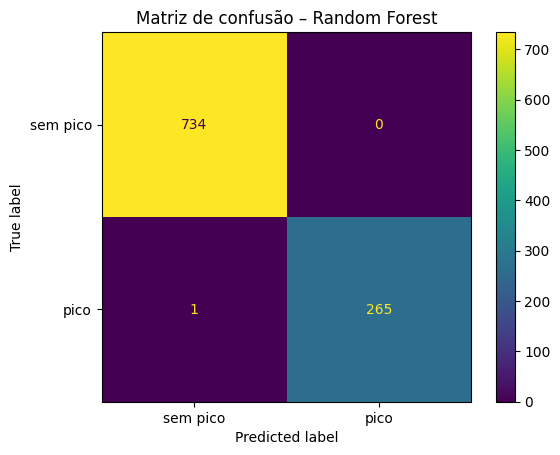

In [7]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["sem pico", "pico"])
plt.title("Matriz de confusão – Random Forest")
plt.show()

### Importância das variáveis

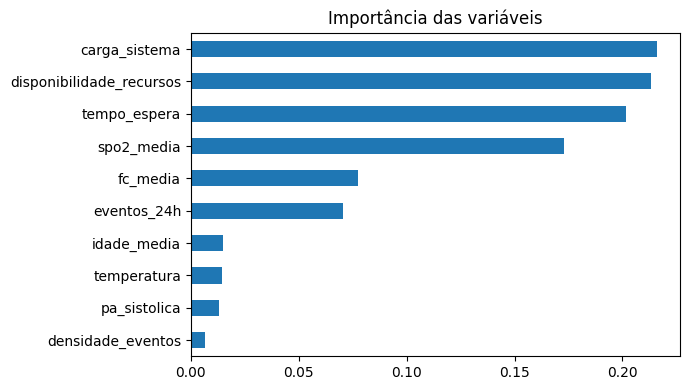

In [8]:
imp = pd.Series(modelo.feature_importances_, index=FEATURES).sort_values()
imp.plot(kind="barh", figsize=(7, 4), title="Importância das variáveis")
plt.tight_layout()
plt.show()

### Interpretação
- A acurácia no teste e na validação cruzada são muito próximas, sem sinal de sobreajuste **nesta base**.
- A matriz mostra 0 falsos positivos e apenas 1 falso negativo; em saúde, o falso negativo é o erro mais grave.
- As variáveis mais importantes (`carga_sistema`, `disponibilidade_recursos`, `tempo_espera`, `spo2_media`, `fc_media`, `eventos_24h`) são exatamente as usadas na regra que gerou o alvo: o modelo reaprendeu a regra. Por isso a acurácia quase perfeita **não** deve ser interpretada como desempenho em dados reais.

## 7. Salvando o modelo
O arquivo é carregado depois pelo Agente Analista de Risco do sistema multiagente.

In [9]:
joblib.dump(modelo, "modelo_risco.joblib")
print("Modelo salvo em modelo_risco.joblib")
# No Colab, para baixar: from google.colab import files; files.download("modelo_risco.joblib")

Modelo salvo em modelo_risco.joblib


## 8. Simulação de previsão para um novo paciente
Dados clínicos simulados (idade, frequência cardíaca, SpO2 etc.). Atenção: a coluna é `disponibilidade_recursos` (com underscore).

In [10]:
novo_caso = pd.DataFrame([{
    "idade_media": 62,
    "carga_sistema": 92,
    "tempo_espera": 75,
    "fc_media": 118,
    "spo2_media": 89,
    "pa_sistolica": 100,
    "temperatura": 37.5,
    "densidade_eventos": 7,
    "eventos_24h": 5,
    "disponibilidade_recursos": 25
}])

modelo_salvo = joblib.load("modelo_risco.joblib")
prob = modelo_salvo.predict_proba(novo_caso[FEATURES])[0, 1]
classe = "ALTO" if prob >= 0.7 else "MODERADO" if prob >= 0.4 else "BAIXO"

print(f"RISCO PREVISTO: {prob:.2f}")
print(f"CLASSIFICAÇÃO: {classe}")

RISCO PREVISTO: 0.96
CLASSIFICAÇÃO: ALTO


## 9. Protocolos acionados (prévia da integração)
No sistema multiagente, o Agente Especialista em Protocolos faz esse cruzamento. Aqui fica uma versão simples para visualizar o resultado.

In [11]:
regras = [
    ("Se SPO2 < 88% → iniciar suporte respiratório imediato",       lambda d, p: d.spo2_media < 88),
    ("Se carga do sistema > 85% → abrir unidades temporárias",       lambda d, p: d.carga_sistema > 85),
    ("Se FC > 120 → iniciar monitoramento intensivo",                lambda d, p: d.fc_media > 120),
    ("Se eventos_24h > 5 → ativar equipe de resposta rápida",        lambda d, p: d.eventos_24h > 5),
    ("Se disponibilidade_recursos < 30% → redistribuir insumos",     lambda d, p: d.disponibilidade_recursos < 30),
    ("Se tempo_espera > 90 min → priorizar triagem emergencial",     lambda d, p: d.tempo_espera > 90),
    ("Se temperatura > 38°C média → iniciar protocolo infeccioso",   lambda d, p: d.temperatura > 38),
    ("Se densidade_eventos > 6 → ativar plano de contingência",      lambda d, p: d.densidade_eventos > 6),
    ("Se PA sistólica < 90 → iniciar protocolo de choque",           lambda d, p: d.pa_sistolica < 90),
    ("Se risco sistêmico alto → ativar estado de emergência",        lambda d, p: p >= 0.7),
]
d = novo_caso.iloc[0]
print("PROTOCOLOS SUGERIDOS:")
for texto, cond in regras:
    if cond(d, prob):
        print("-", texto)

PROTOCOLOS SUGERIDOS:
- Se carga do sistema > 85% → abrir unidades temporárias
- Se disponibilidade_recursos < 30% → redistribuir insumos
- Se densidade_eventos > 6 → ativar plano de contingência
- Se risco sistêmico alto → ativar estado de emergência
